# Chapter 30: Social Choice Mechanisms and Strategy-Proofness

This notebook reruns four worked examples from the chapter: a median rule with phantom voters, Clarke pivot payments for a flood barrier (Green-Laffont), log-score peer prediction, and quadratic voting. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def generalized_median(reports, phantoms):
    """Median of the reports pooled with fixed phantom points (Moulin's generalized median).

    Principle: generalized-median-voter-schemes. Returns a dict with the sorted list and the
    outcome (the middle order statistic). Book (ch030): reports 15, 35, 60, 75, 90 and phantoms
    40, 50, 55, 65 give the list 15, 35, 40, 50, 55, 60, 65, 75, 90 and f(r) = 55; reporting 45
    instead of 60 gives 50 and reporting 100 still gives 55. Implemented by Part 4 (stub unused by Part 2).
    """
    pooled = sorted(list(reports) + list(phantoms))
    if len(pooled) % 2 == 0:
        raise ValueError("generalized_median needs an odd number of reports plus phantoms")
    return {"sorted": pooled, "outcome": pooled[len(pooled) // 2], "position": len(pooled) // 2 + 1}


def clarke_pivot_public_good(values, cost):
    """Clarke pivot payments for a binary public project built when total value covers cost.

    Principle: green-laffont-impossibility. Each owner pays the others' best welfare without them minus
    the others' welfare (project cost included) under the chosen decision. Book (ch030): values 70, 55, 15
    and cost 110 give total 140, net 30, payments 40, 25, 0, revenue 65, gap 45, utilities 30, 30, 15.
    """
    total = sum(values)
    build = total >= cost
    payments, others_list = [], []
    for v in values:
        others = total - v
        without = max(others - cost, 0.0)
        with_i = (others - cost) if build else 0.0
        payments.append(without - with_i)
        others_list.append(others)
    revenue = sum(payments)
    utilities = [(v if build else 0.0) - p for v, p in zip(values, payments)]
    return {"total": total, "net": total - cost, "build": build, "others": others_list, "payments": payments,
            "revenue": revenue, "deficit": (cost - revenue) if build else 0.0, "utilities": utilities}


def log_score_expected(belief, report, shift=0.0):
    """Expected logarithmic score of a reported forecast under a belief: shift + sum_k belief_k ln(report_k).

    Principle: peer-prediction-mechanism. ``belief`` and ``report`` are probability lists over the
    peer's labels. Book (ch030): belief (0.75, 0.25), truthful report (0.75, 0.25) gives -0.562; false
    report (0.25, 0.75) gives -1.112; the gap is ln(3)/2 = 0.549; with (0.5, 0.5) every report scores ln 0.5 = -0.693.
    A constant shift (book: 1.2) moves every score equally.
    """
    return shift + sum(b * math.log(r) for b, r in zip(belief, report) if b > 0)


def quadratic_votes(values):
    """Continuous quadratic-voting benchmark: votes v_i = V_i / 2, credits v_i^2, tally sum v_i.

    Principle: quadratic-voting. Book (ch030): supporter V = 24 and four opponents at -4 give votes 12 and
    -2 each, credits 144 and 4 each (16 total), tally 12 + 4(-2) = 4 (passes); V = 14 gives 7 - 8 = -1 (fails).
    """
    votes = [V / 2 for V in values]
    credits = [v * v for v in votes]
    tally = sum(votes)
    return {"votes": votes, "credits": credits, "tally": tally,
            "outcome": "passes" if tally > 1e-12 else ("tie" if abs(tally) <= 1e-12 else "fails")}


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(generalized_median=generalized_median)


auctions = SimpleNamespace(clarke_pivot_public_good=clarke_pivot_public_good, log_score_expected=log_score_expected, quadratic_votes=quadratic_votes)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'generalized-median-voter-schemes': {'peaks': [15, 35, 60, 75, 90],
                                      'phantoms': [40, 50, 55, 65],
                                      'outcome': 55,
                                      'distance': 5,
                                      'report_high': 100,
                                      'outcome_high': 55,
                                      'report_low': 45,
                                      'outcome_low': 50,
                                      'distance_low': 10},
 'green-laffont-impossibility': {'cost': 110,
                                 'values': [70, 55, 15],
                                 'total': 140,
                                 'net': 30,
                                 'payments': [40, 25, 0],
                                 'revenue': 65,
                                 'gap': 45,
                                 'utilities': [30, 30, 15]},
 'peer-prediction-mechanism': {'q': 0.75,
                               'truthful': -0.562,
                               'false': -1.112,
                               'advantage': 0.549,
                               'shift': 1.2,
                               'uninformative': -0.693},
 'quadratic-voting': {'V': 24,
                      'V_alt': 14,
                      'opponents': 4,
                      'V_opp': -4,
                      'votes': 12,
                      'credits': 144,
                      'opp_votes': -2,
                      'opp_credits_total': 16,
                      'tally': 4,
                      'votes_alt': 7,
                      'credits_alt': 49,
                      'tally_alt': -1},
 'constructed': {'generalized-median-voter-schemes': {'reports': [30, 45, 60, 100]},
                 'green-laffont-impossibility': {'cost': [100, 120], 'v3': [5, 25]},
                 'peer-prediction-mechanism': {'q': [0.6, 0.9]},
                 'quadratic-voting': {'V': [10, 30], 'opponents': [3]}}}


PHANTOMS = [40, 50, 55, 65]


def median_picture(r=60):
    reports = [15, 35, r, 75, 90]
    res = games.generalized_median(reports, PHANTOMS)
    out = res["outcome"]
    dist = abs(60 - out)
    fig, ax = new_figure()
    ax.axhline(1.0, color=PALETTE["grey"], linewidth=1)
    ax.axhline(0.5, color=PALETTE["grey"], linewidth=1)
    others = [15, 35, 75, 90]
    ax.scatter(others, [1.0] * 4, s=70, color=PALETTE["navy"], zorder=5, label="other districts' reports")
    ax.scatter([r], [1.0], s=110, color=PALETTE["gold"], zorder=6, label=f"district with peak 60 reports {r}")
    ax.scatter(PHANTOMS, [0.5] * 4, s=80, marker="D", color=PALETTE["teal"], zorder=5, label="phantoms 40, 50, 55, 65")
    ax.scatter([60], [1.35], s=60, marker="v", color=PALETTE["ink"], zorder=5)
    label(ax, 60, 1.35, "true peak 60", dx=8, dy=0, va="center")
    vline(ax, out, f"outcome {num(out, 0)}", col="terracotta", y_frac=0.12, ha="right")
    ax.set_xlim(0, 105)
    ax.set_ylim(0.2, 1.9)
    ax.set_yticks([0.5, 1.0], ["phantoms", "reports"])
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Conservation target")
    ax.set_ylabel("Point type")
    listed = ", ".join(num(v, 0) for v in res["sorted"])
    truthful = r == 60
    verdict = ("This is the truthful report." if truthful else
               f"Compared with the truthful distance 5, this report is {'equally good' if dist == 5 else 'worse'}.")
    metrics = {"Report of the peak-60 district": num(r, 0), "Outcome (5th of 9)": num(out, 0),
               "Distance from 60": num(dist, 0), "Better than truthful": "no"}
    interp = (f"The nine points in order are {listed}; the fifth is {num(out, 0)}. The district's distance is "
              f"|60 - {num(out, 0)}| = {num(dist, 0)}. {verdict} No report brings the outcome closer to 60, because the "
              f"phantom at 55 caps upward moves and lower reports pull the median down.")
    steps = [f"Sorted: {listed}", f"Fifth value: {num(out, 0)}", f"Distance = |60 - {num(out, 0)}| = {num(dist, 0)}"]
    alt = (f"Number line with the five reports, four phantoms and the outcome {num(out, 0)} when the district with peak "
           f"60 reports {r}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def clarke_picture(c=110, v3=15):
    values = [70, 55, v3]
    res = auctions.clarke_pivot_public_good(values, c)
    fig, ax = new_figure()
    names = ["Owner 1 (70)", "Owner 2 (55)", f"Owner 3 ({v3})", "Revenue"]
    bars = res["payments"] + [res["revenue"]]
    cols = [PALETTE["navy"], PALETTE["teal"], PALETTE["gold"], PALETTE["ink"]]
    xs = np.arange(4)
    ax.bar(xs, bars, color=cols, width=0.55)
    for x, v in zip(xs, bars):
        label(ax, x, v, num(v, 0), dx=0, dy=3, ha="center")
    ax.axhline(c, color=PALETTE["terracotta"], linestyle="dashed", linewidth=1.5, label=f"barrier cost {c}")
    if res["deficit"] > 0:
        ax.bar([3], [res["deficit"]], bottom=[res["revenue"]], color=PALETTE["terracotta"], alpha=0.25, width=0.55,
               label=f"financing gap {num(res['deficit'], 0)}")
    ax.set_xticks(xs, names)
    ax.set_ylim(0, 150)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Clarke pivot payment")
    ax.set_ylabel("Thousand dollars")
    p = res["payments"]
    lines = []
    for i, (v, o) in enumerate(zip(values, res["others"]), start=1):
        if o >= c:
            lines.append(f"Owner {i}: others {num(o, 0)} >= {c}, still built, pays ({num(o, 0)} - {c}) - "
                         f"({num(o, 0)} - {c}) = {num(p[i - 1], 0)}")
        else:
            lines.append(f"Owner {i}: others {num(o, 0)} < {c}, pays 0 - ({num(o, 0)} - {c}) = {num(p[i - 1], 0)}")
    u = res["utilities"]
    metrics = {"Total benefit": num(res["total"], 0), "Net value": num(res["net"], 0),
               "Payments": ", ".join(num(x, 0) for x in p), "Revenue": num(res["revenue"], 0),
               "Financing gap": num(res["deficit"], 0), "Utilities": ", ".join(num(x, 0) for x in u)}
    interp = (f"Total benefit 70 + 55 + {v3} = {num(res['total'], 0)} covers the cost {c}, so the barrier is built with "
              f"net value {num(res['total'], 0)} - {c} = {num(res['net'], 0)}. " + ". ".join(lines) + ". Revenue "
              f"{num(p[0], 0)} + {num(p[1], 0)} + {num(p[2], 0)} = {num(res['revenue'], 0)} leaves a gap of {c} - "
              f"{num(res['revenue'], 0)} = {num(res['deficit'], 0)}: efficient and truthful, but not self-financing.")
    steps = [f"Total = 70 + 55 + {v3} = {num(res['total'], 0)}", f"Net = {num(res['total'], 0)} - {c} = {num(res['net'], 0)}"]
    steps += lines
    steps += [f"Revenue = {num(p[0], 0)} + {num(p[1], 0)} + {num(p[2], 0)} = {num(res['revenue'], 0)}",
              f"Gap = {c} - {num(res['revenue'], 0)} = {num(res['deficit'], 0)}"]
    alt = (f"Bars of the three Clarke payments {', '.join(num(x, 0) for x in p)} and revenue {num(res['revenue'], 0)} "
           f"against the cost line at {c}, with a gap of {num(res['deficit'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def peer_scores(q, shift):
    t = auctions.log_score_expected((q, 1 - q), (q, 1 - q), shift)
    f = auctions.log_score_expected((q, 1 - q), (1 - q, q), shift)
    return t, f


def peer_picture(q=0.75, shift=0):
    t, f = peer_scores(q, shift)
    adv = t - f
    fig, ax = new_figure()
    xs = np.arange(2)
    vals = [t, f]
    ax.bar(xs, vals, color=[PALETTE["teal"], PALETTE["terracotta"]], width=0.55)
    for x, v in zip(xs, vals):
        label(ax, x, v, num(v, 4), dx=0, dy=-4 if v < 0 else 3, ha="center", va="top" if v < 0 else "bottom")
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, ["Truthful report", "False report"])
    ax.set_ylim(-2.6, 1.6)
    ax.set_xlim(-0.6, 1.9)
    ax.annotate("", xy=(1.45, t), xytext=(1.45, f), arrowprops={"arrowstyle": "<->", "color": PALETTE["ink"]})
    label(ax, 1.5, (t + f) / 2, f"gap {num(adv, 4)}", dx=4, dy=0, va="center")
    ax.set_xlabel("Report after seeing G")
    ax.set_ylabel("Expected log score")
    sh = f"{num(shift, 1)} + " if shift else ""
    tie = abs(adv) < 1e-12
    verdict = ("Both reports score the same, so truth telling is not strictly better: the signal says nothing about "
               "the peer." if tie else "Truth telling is strictly better.")
    metrics = {"Truthful score": num(t, 4), "False score": num(f, 4), "Truthful advantage": num(adv, 4),
               "Strictly truthful": "no, a tie" if tie else "yes"}
    q2 = num(1 - q, 2)
    interp = (f"Truthful: {sh}{num(q, 2)} ln {num(q, 2)} + {q2} ln {q2} = {num(t, 4)}. False: {sh}{num(q, 2)} ln {q2} + "
              f"{q2} ln {num(q, 2)} = {num(f, 4)}. Advantage {num(t, 4)} - ({num(f, 4)}) = {num(adv, 4)}. {verdict}"
              + (f" The constant {num(shift, 1)} moves both scores and leaves the gap unchanged." if shift else ""))
    steps = [f"Truthful = {sh}{num(q, 2)} ln {num(q, 2)} + {q2} ln {q2} = {num(t, 4)}",
             f"False = {sh}{num(q, 2)} ln {q2} + {q2} ln {num(q, 2)} = {num(f, 4)}",
             f"Advantage = {num(t, 4)} - ({num(f, 4)}) = {num(adv, 4)}"]
    alt = (f"Two bars: truthful expected score {num(t, 4)} and false {num(f, 4)} at agreement probability {num(q, 2)}, "
           f"gap {num(adv, 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def qv_picture(value=24, n=4):
    V = value
    res = auctions.quadratic_votes([value] + [-4] * n)
    vs, cr = res["votes"][0], res["credits"][0]
    tally = res["tally"]
    fig, ax = new_figure()
    names = ["Supporter"] + [f"Opp. {i}" for i in range(1, n + 1)] + ["Net"]
    vals = res["votes"] + [tally]
    cols = [PALETTE["teal"]] + [PALETTE["terracotta"]] * n + [PALETTE["ink"]]
    xs = np.arange(len(vals))
    ax.bar(xs, vals, color=cols, width=0.6)
    for x, v, c in zip(xs, vals, [cr] + [4] * n + [None]):
        text = num(v, 1) if c is None else f"{num(v, 1)} ({num(c, 0)} cr.)"
        label(ax, x, v, text, dx=0, dy=3 if v >= 0 else -3, ha="center", va="bottom" if v >= 0 else "top")
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_ylim(-6, 19)
    ax.set_xlabel("Participant")
    ax.set_ylabel("Votes bought (credits in parentheses)")
    out = res["outcome"]
    metrics = {"Supporter votes": num(vs, 1), "Supporter credits": num(cr, 2), "Opposition votes": num(-2 * n, 0),
               "Opposition credits": num(4 * n, 0), "Net tally": num(tally, 1), "Outcome": out}
    opp = plural(n, "opponent")
    interp = (f"The supporter buys {value}/2 = {num(vs, 1)} votes for {num(vs, 1)}^2 = {num(cr, 2)} credits. Each of the "
              f"{opp} buys -4/2 = -2 votes for 4 credits, {num(4 * n, 0)} in all. Net tally {num(vs, 1)} + {n}(-2) = "
              f"{num(tally, 1)}, so the proposal {out}. With {opp} a supporter value of {4 * n} ties.")
    steps = [f"Supporter votes = {value}/2 = {num(vs, 1)}, credits = {num(cr, 2)}", "Each opponent: -4/2 = -2 votes, 4 credits",
             f"Tally = {num(vs, 1)} + {n}(-2) = {num(tally, 1)}", f"Outcome: {out}"]
    alt = (f"Vote bars: supporter {num(vs, 1)} votes against {opp} at -2 each, net {num(tally, 1)}; the proposal {out}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Generalized-median voter schemes: phantoms pin the median

Five districts report peaks 15, 35, 60, 75, 90; phantoms sit at 40, 50, 55, 65. The outcome is the fifth of nine ordered points.

$$15,35,40,50,55,60,65,75,90 \qquad f(r)=55 \qquad |60-55|=5$$

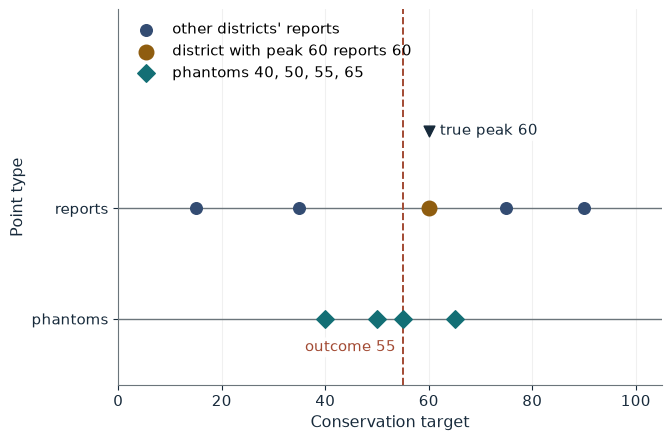

Report of the peak-60 district  60
Outcome (5th of 9)              55
Distance from 60                5
Better than truthful            no

Worked steps:
  1. Sorted: 15, 35, 40, 50, 55, 60, 65, 75, 90
  2. Fifth value: 55
  3. Distance = |60 - 55| = 5

The nine points in order are 15, 35, 40, 50, 55, 60, 65, 75, 90; the fifth is 55. The district's distance is |60 - 55| = 5. This is the truthful report. No report brings the outcome closer to 60, because the phantom at 55 caps upward moves and lower reports pull the median down.


In [2]:
show(median_picture(r=60))

Change one input, `r`, and hold the others at the book's values:

In [3]:
sweep(median_picture, 'r', [30, 45, 60, 100], {}, ['Outcome (5th of 9)', 'Distance from 60'])

r | Outcome (5th of 9) | Distance from 60
30 | 50 | 10
45 | 50 | 10
60 | 55 | 5
100 | 55 | 5


Truthful reporting gives 55, distance 5. Reporting 100 still gives 55; reporting 45 or 30 drops the outcome to 50, distance 10. No misreport helps.

## 2. Green-Laffont impossibility: Clarke payments fall short

Values 70, 55, 15 (thousand dollars), cost 110.

$$70+55+15=140, \qquad 140-110=30, \qquad 0-(-40)=40, \qquad 40+25+0=65, \qquad 110-65=45$$

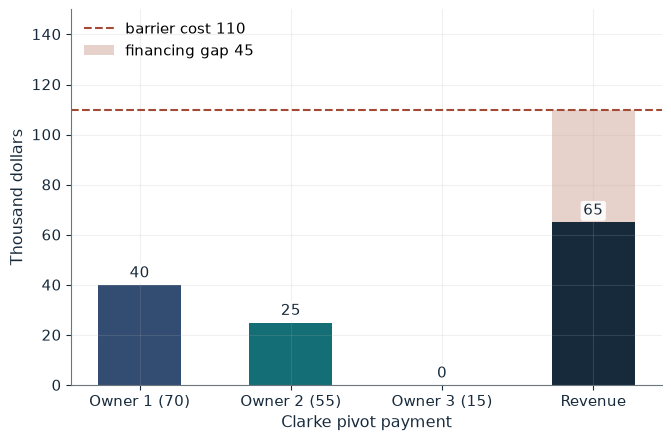

Total benefit  140
Net value      30
Payments       40, 25, 0
Revenue        65
Financing gap  45
Utilities      30, 30, 15

Worked steps:
  1. Total = 70 + 55 + 15 = 140
  2. Net = 140 - 110 = 30
  3. Owner 1: others 70 < 110, pays 0 - (70 - 110) = 40
  4. Owner 2: others 85 < 110, pays 0 - (85 - 110) = 25
  5. Owner 3: others 125 >= 110, still built, pays (125 - 110) - (125 - 110) = 0
  6. Revenue = 40 + 25 + 0 = 65
  7. Gap = 110 - 65 = 45

Total benefit 70 + 55 + 15 = 140 covers the cost 110, so the barrier is built with net value 140 - 110 = 30. Owner 1: others 70 < 110, pays 0 - (70 - 110) = 40. Owner 2: others 85 < 110, pays 0 - (85 - 110) = 25. Owner 3: others 125 >= 110, still built, pays (125 - 110) - (125 - 110) = 0. Revenue 40 + 25 + 0 = 65 leaves a gap of 110 - 65 = 45: efficient and truthful, but not self-financing.


In [4]:
show(clarke_picture(c=110, v3=15))

Change one input, `v3`, and hold the others at the book's values:

In [5]:
sweep(clarke_picture, 'v3', [5, 15, 25], {'c': 110}, ['Payments', 'Revenue', 'Financing gap'])

v3 | Payments | Revenue | Financing gap
5 | 50, 35, 0 | 85 | 25
15 | 40, 25, 0 | 65 | 45
25 | 30, 15, 0 | 45 | 65


Payments 40, 25 and 0 raise 65 against a cost of 110, a gap of 45. A higher third value makes the others less pivotal, so revenue falls (85, 65, 45) and the gap widens.

## 3. Peer-prediction mechanism: paying for honest reports

With agreement probability $q=0.75$:

$$0.75\ln(0.75)+0.25\ln(0.25)\approx -0.562, \qquad 0.75\ln(0.25)+0.25\ln(0.75)\approx -1.112, \qquad \frac{1}{2}\ln(3)\approx 0.549$$

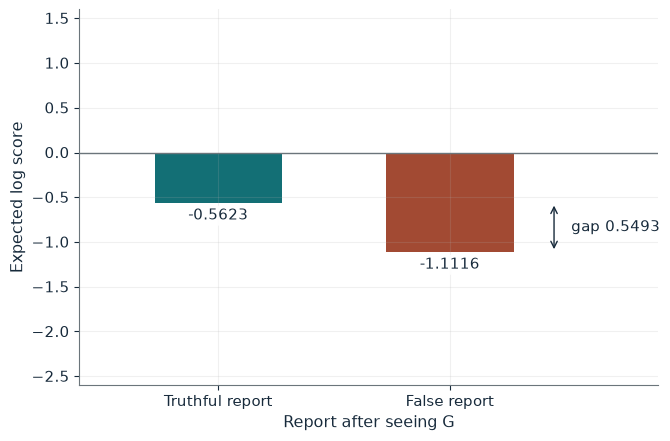

Truthful score      -0.5623
False score         -1.1116
Truthful advantage  0.5493
Strictly truthful   yes

Worked steps:
  1. Truthful = 0.75 ln 0.75 + 0.25 ln 0.25 = -0.5623
  2. False = 0.75 ln 0.25 + 0.25 ln 0.75 = -1.1116
  3. Advantage = -0.5623 - (-1.1116) = 0.5493

Truthful: 0.75 ln 0.75 + 0.25 ln 0.25 = -0.5623. False: 0.75 ln 0.25 + 0.25 ln 0.75 = -1.1116. Advantage -0.5623 - (-1.1116) = 0.5493. Truth telling is strictly better.


In [6]:
show(peer_picture(q=0.75, shift=0))

Change one input, `q`, and hold the others at the book's values:

In [7]:
sweep(peer_picture, 'q', [0.5, 0.6, 0.75, 0.9], {'shift': 0}, ['Truthful score', 'False score', 'Truthful advantage'])

q | Truthful score | False score | Truthful advantage
0.5 | -0.6931 | -0.6931 | 0.0000
0.6 | -0.6730 | -0.7541 | 0.0811
0.75 | -0.5623 | -1.1116 | 0.5493
0.9 | -0.3251 | -2.0829 | 1.7578


At 0.75 the truthful report beats the false one by 0.5493 = ln(3)/2. At 0.5 both score ln 0.5 = -0.6931, so honesty is no longer strictly better. Adding 1.2 to every score leaves the gap unchanged.

## 4. Quadratic voting: intensity versus numbers

Votes $v=V/2$ cost $v^2$ credits. Supporter $V=24$, four opponents at $V=-4$.

$$v_S=\frac{24}{2}=12 \qquad v_O=\frac{-4}{2}=-2 \qquad 12+4(-2)=4 \qquad 7-8=-1$$

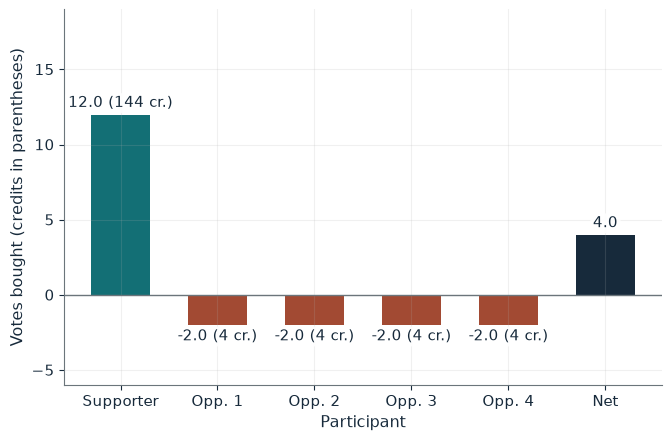

Supporter votes     12.0
Supporter credits   144.00
Opposition votes    -8
Opposition credits  16
Net tally           4.0
Outcome             passes

Worked steps:
  1. Supporter votes = 24/2 = 12.0, credits = 144.00
  2. Each opponent: -4/2 = -2 votes, 4 credits
  3. Tally = 12.0 + 4(-2) = 4.0
  4. Outcome: passes

The supporter buys 24/2 = 12.0 votes for 12.0^2 = 144.00 credits. Each of the 4 opponents buys -4/2 = -2 votes for 4 credits, 16 in all. Net tally 12.0 + 4(-2) = 4.0, so the proposal passes. With 4 opponents a supporter value of 16 ties.


In [8]:
show(qv_picture(value=24, n=4))

Change one input, `value`, and hold the others at the book's values:

In [9]:
sweep(qv_picture, 'value', [10, 14, 24, 30], {'n': 4}, ['Supporter votes', 'Net tally', 'Outcome'])

value | Supporter votes | Net tally | Outcome
10 | 5.0 | -3.0 | fails
14 | 7.0 | -1.0 | fails
24 | 12.0 | 4.0 | passes
30 | 15.0 | 7.0 | passes


At V = 24 the supporter's 12 votes beat 8 opposing votes and the proposal passes; at 14 the tally is 7 - 8 = -1 and it fails. The tie with four opponents is V = 16.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

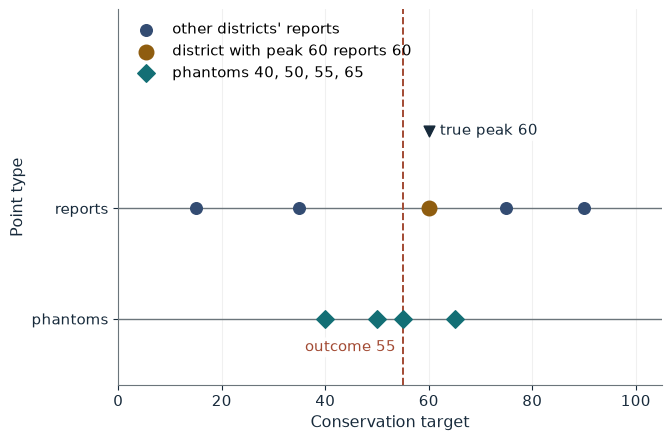

Report of the peak-60 district  60
Outcome (5th of 9)              55
Distance from 60                5
Better than truthful            no

Worked steps:
  1. Sorted: 15, 35, 40, 50, 55, 60, 65, 75, 90
  2. Fifth value: 55
  3. Distance = |60 - 55| = 5

The nine points in order are 15, 35, 40, 50, 55, 60, 65, 75, 90; the fifth is 55. The district's distance is |60 - 55| = 5. This is the truthful report. No report brings the outcome closer to 60, because the phantom at 55 caps upward moves and lower reports pull the median down.


In [10]:
show(median_picture(r=60))

## Practice

**1.** If the district with peak 60 reports 30, what is the outcome and its distance from 60?

<details><summary>Answer</summary>

Sorted 15, 30, 35, 40, 50, 55, 65, 75, 90; the fifth value is 50, distance 10, worse than the truthful 5.

</details>

**2.** At cost 110 and third value 25, what is the financing gap?

<details><summary>Answer</summary>

Payments 0 - (80 - 110) = 30, 0 - (95 - 110) = 15 and 0; revenue 45; gap 110 - 45 = 65.

</details>

**3.** With V = 14 and three opponents, does the proposal pass?

<details><summary>Answer</summary>

7 + 3(-2) = 1 > 0, so it passes.

</details>